# 2-D SINGLE-SLIT DIFFRACTION 

In [25]:
from matplotlib import pyplot as plt
import numpy as np
import scipy

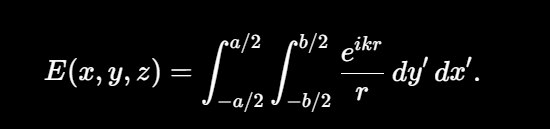

In [46]:
lam = 532*10**-9
k = 2*np.pi/lam
z = 0.01 #1 cm

a = 50.*10**-6
b = 50.*10**-6

x = np.linspace(-1*a,1*a,100) #points along screen
y = np.linspace(-1*b,1*b,100) #points along screen
dxprime = 1e-7
dyprime = 1e-7
xprime = np.linspace(-a/2,a/2,int(a/dxprime +1)) #limits of integration
yprime = np.linspace(-b/2,b/2,int(b/dyprime +1)) #limits of integration

## Numerical full Huygens Integral

This is really slow. Want a good picture over a larger range? Use the analytical solution part below

In [47]:
E = np.zeros((len(y), len(x)), dtype = np.complex128)

Xp, Yp = np.meshgrid(xprime, yprime, indexing='ij')

for i in range(len(y)):
    print(i)
    for s in range(len(x)):

        r = np.sqrt(
            (x[s]-Xp)**2 +
            (y[i]-Yp)**2 +
            z**2
        )

        integrand = np.exp(1j*k*r)/r

        E[i,s] = np.trapz(
            np.trapz(integrand, yprime, axis=1),
            xprime
        )

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


In [48]:
I_num = np.abs(E)**2
I_num /= np.max(I_num)

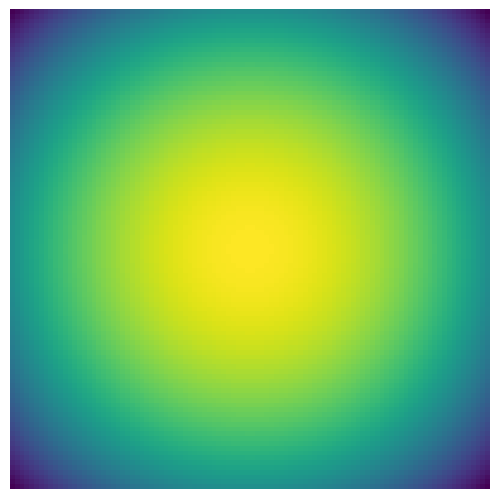

In [50]:
fig, ax = plt.subplots()

ax.imshow(np.log10(I_num), cmap='viridis')

ax.set_axis_off()

fig.subplots_adjust(0,0,1,1)

plt.show()

## Analytical Fraunhofer

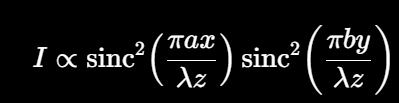

In [51]:
betax = np.pi*a*x/(lam*z)
betay = np.pi*b*y/(lam*z)
I_fraun = np.outer(np.sinc(betay/np.pi)**2., np.sinc(betax/np.pi)**2.)

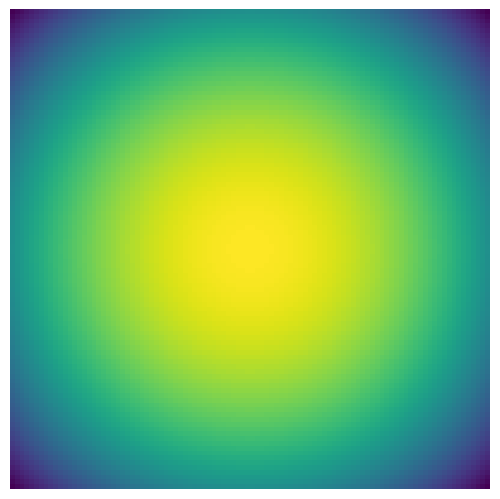

In [52]:
fig, ax = plt.subplots()

ax.imshow(np.log10(I_fraun), cmap='viridis')

ax.set_axis_off()

fig.subplots_adjust(0,0,1,1)

plt.show()